# 🚢 Titanic Survival Prediction — Machine Learning with Python

**Author:** Edith Tostado Ortiz
**Goal:** Predict whether a Titanic passenger survived (1) or not (0) from information such as sex, age, ticket class and family size.
**Type of problem:** Supervised learning, binary classification.

### Workflow
1. Setup & data loading
2. Exploratory Data Analysis (EDA)
3. Data cleaning (missing values)
4. Feature engineering
5. Encoding categorical variables
6. Train / test split
7. Baseline model: Logistic Regression
8. Error analysis: confusion matrix
9. Model comparison & overfitting
10. Predictions on new (made-up) passengers
11. Model explainability (coefficients)

**Final result:** Logistic Regression reached **83.8% accuracy** on unseen data, with no overfitting.

## 1. Setup & data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

sns.set_theme(style="whitegrid")

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print(df.shape)   # 891 passengers, 12 columns
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


**Column guide**

| Column | Meaning |
|---|---|
| `Survived` | Target: 0 = did not survive, 1 = survived |
| `Pclass` | Ticket class (1st, 2nd, 3rd) |
| `Sex`, `Age` | Sex and age |
| `SibSp` | # of **sib**lings + **sp**ouse aboard |
| `Parch` | # of **par**ents + **ch**ildren aboard |
| `Fare` | Ticket price |
| `Cabin` | Cabin number |
| `Embarked` | Port: C = Cherbourg, Q = Queenstown, S = Southampton |

Three columns have missing values: `Age` (177), `Cabin` (687) and `Embarked` (2).

In [3]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## 2. Exploratory Data Analysis (EDA)
Before training any model, I looked for patterns myself. Because `Survived` is 0/1, its **mean is the survival rate**.

Overall survival rate: 38.4%


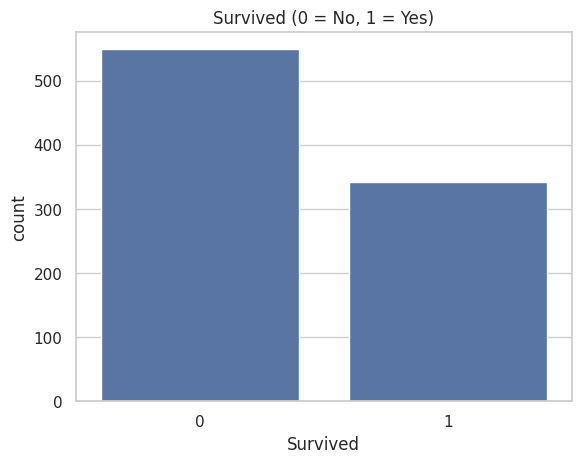

In [4]:
print(f"Overall survival rate: {df['Survived'].mean()*100:.1f}%")
sns.countplot(x='Survived', data=df)
plt.title('Survived (0 = No, 1 = Yes)')
plt.show()

Sex
female    74.2
male      18.9
Name: Survived, dtype: float64


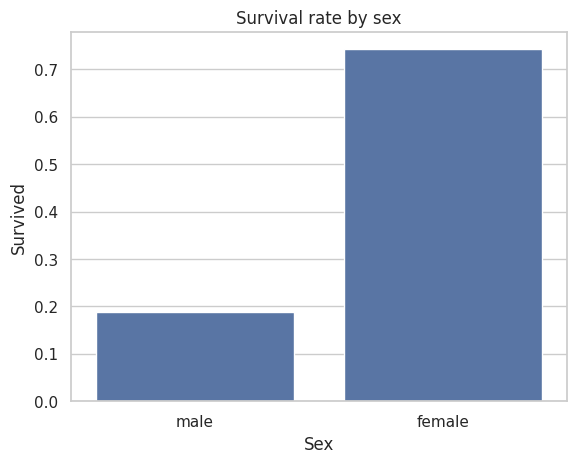

In [5]:
print((df.groupby('Sex')['Survived'].mean() * 100).round(1))
sns.barplot(x='Sex', y='Survived', data=df, errorbar=None)
plt.title('Survival rate by sex')
plt.show()

Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64


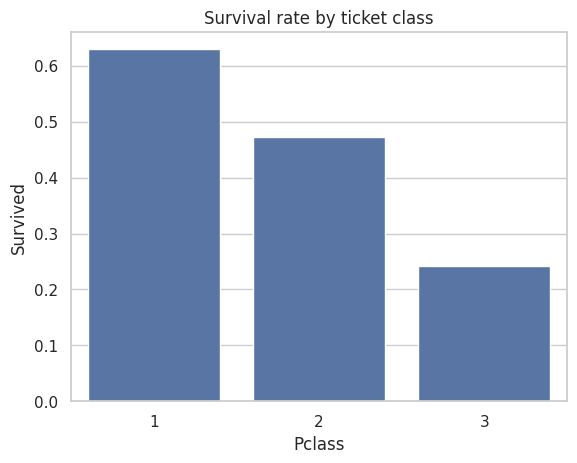

In [6]:
print((df.groupby('Pclass')['Survived'].mean() * 100).round(1))
sns.barplot(x='Pclass', y='Survived', data=df, errorbar=None)
plt.title('Survival rate by ticket class')
plt.show()

Age
Child (0-10)           59.4
Teen (10-18)           42.7
Young adult (18-30)    35.6
Adult (30-50)          42.3
Senior (50-80)         34.4
Name: Survived, dtype: float64


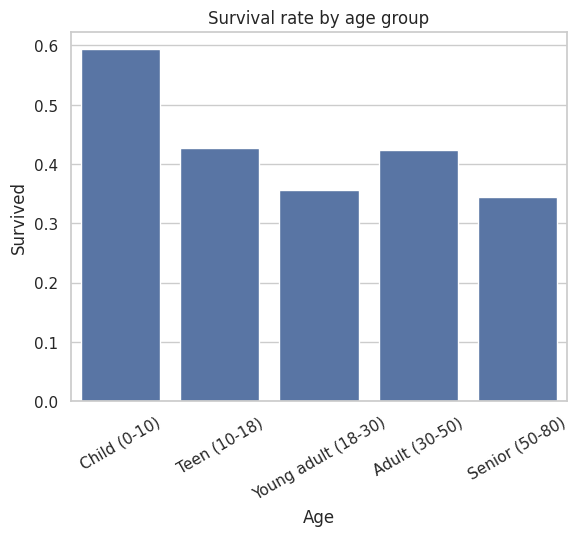

In [7]:
age_groups = pd.cut(df['Age'], bins=[0, 10, 18, 30, 50, 80],
                    labels=['Child (0-10)', 'Teen (10-18)', 'Young adult (18-30)',
                            'Adult (30-50)', 'Senior (50-80)'])
print((df.groupby(age_groups, observed=True)['Survived'].mean() * 100).round(1))
sns.barplot(x=age_groups, y=df['Survived'], errorbar=None)
plt.title('Survival rate by age group')
plt.xticks(rotation=30)
plt.show()

**EDA findings**
- Only **38%** of passengers survived.
- **Women 74%** vs **men 19%**: the strongest signal ("women and children first").
- **1st class 63%** vs **3rd class 24%**: ticket class mattered a lot.
- **Children (0–10)** had the highest survival rate of any age group.

## 3. Data cleaning
Models can't handle empty cells, so each missing column gets a strategy:
- **Embarked** (2 missing) → fill with the most common port (mode).
- **Cabin** (77% missing) → too empty to fill, but *having* a cabin is a signal. Convert to `HasCabin` (1/0) and drop the original.
- **Age** (20% missing) → fill with the **median age of the passenger's class + sex group**, which is more accurate than one global value. Median is used because it isn't pulled by outliers.

In [8]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

df['HasCabin'] = df['Cabin'].notnull().astype(int)
df = df.drop(columns=['Cabin'])
print((df.groupby('HasCabin')['Survived'].mean() * 100).round(1))

HasCabin
0    30.0
1    66.7
Name: Survived, dtype: float64


In [9]:
print(df.groupby(['Pclass', 'Sex'])['Age'].median())
df['Age'] = df.groupby(['Pclass', 'Sex'])['Age'].transform(lambda x: x.fillna(x.median()))
df.isnull().sum()   # all zeros ✅

Pclass  Sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: Age, dtype: float64


PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
HasCabin       0
dtype: int64

## 4. Feature engineering
New columns that give the model better clues:
- **FamilySize** = SibSp + Parch + 1
- **IsAlone** = 1 if traveling alone
- **Title** extracted from the name (Mr, Mrs, Miss, Master, Rare). A title combines sex, age and marital status in one feature; *Master* was the title for young boys.

IsAlone
0    50.6
1    30.4
Name: Survived, dtype: float64


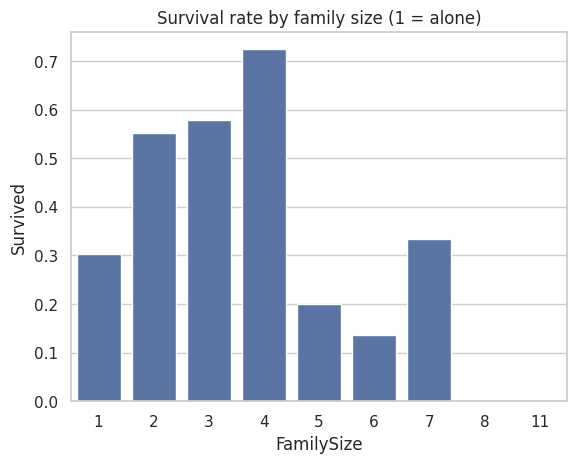

In [10]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

print((df.groupby('IsAlone')['Survived'].mean() * 100).round(1))
sns.barplot(x='FamilySize', y='Survived', data=df, errorbar=None)
plt.title('Survival rate by family size (1 = alone)')
plt.show()

Small families (2–4) did best; people traveling alone and very large families (5+) did worst.

In [11]:
df['Title'] = df['Name'].str.extract(r',\s*([^\.]+)\.', expand=False)
df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
df['Title'] = df['Title'].apply(lambda t: t if t in ['Mr', 'Mrs', 'Miss', 'Master'] else 'Rare')

summary = df.groupby('Title')['Survived'].agg(passengers='count', survival_rate='mean')
summary['survival_rate'] = (summary['survival_rate'] * 100).round(1)
summary.sort_values('survival_rate', ascending=False)

,passengers,survival_rate
Title,,
Mrs,126,79.4
Miss,185,70.3
Master,40,57.5
Rare,23,34.8
Mr,517,15.7


*Mrs* (79%) and *Miss* (70%) survived the most, *Mr* (16%) the least. *Master* (boys) reached 57%: the "children first" rule shows up clearly.

## 5. Encoding categorical variables
Models only understand numbers.
- Drop columns with no predictive value: `PassengerId`, `Name` (title already extracted), `Ticket`.
- `Sex` → 0/1.
- `Embarked` and `Title` → **One-Hot Encoding** (one 0/1 column per option). Plain 0/1/2 labels would wrongly imply an order.

In [12]:
df = df.drop(columns=['PassengerId', 'Name', 'Ticket'])
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df = pd.get_dummies(df, columns=['Embarked', 'Title'], dtype=int)

print(df.shape)   # (891, 18)
df.head()

(891, 18)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,3,0,22.0,1,0,7.2500,0,2,0,0,0,1,0,0,1,0,0
1,1,1,1,38.0,1,0,71.2833,1,2,0,1,0,0,0,0,0,1,0
2,1,3,1,26.0,0,0,7.9250,0,1,1,0,0,1,0,1,0,0,0
3,1,1,1,35.0,1,0,53.1000,1,2,0,0,0,1,0,0,0,1,0
4,0,3,0,35.0,0,0,8.0500,0,1,1,0,0,1,0,0,1,0,0


## 6. Train / test split
- **X** = features (the clues), **y** = `Survived` (the answer). The answer is never inside X, which would be *data leakage*.
- **80%** for training, **20%** held out as an "exam" the model never sees while learning.
- `stratify=y` keeps the same ~38% survival rate in both sets.

In [13]:
X = df.drop(columns=['Survived'])
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Survival rate — train: {y_train.mean()*100:.1f}% | test: {y_test.mean()*100:.1f}%")

Train: (712, 17) | Test: (179, 17)
Survival rate — train: 38.3% | test: 38.5%


## 7. Baseline model: Logistic Regression
Logistic Regression assigns a weight ("points") to each feature, adds them up and turns the total into a probability. Above 50% → survived.

*Reference point:* predicting "nobody survived" would score ~62%, so anything well above that means the model learned real patterns.

In [14]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print(f"Train accuracy: {model.score(X_train, y_train)*100:.1f}%")
print(f"Test accuracy:  {accuracy_score(y_test, predictions)*100:.1f}%")

Train accuracy: 83.4%
Test accuracy:  83.8%


Train and test scores are almost identical → the model **generalizes** instead of memorizing.

## 8. Error analysis: confusion matrix

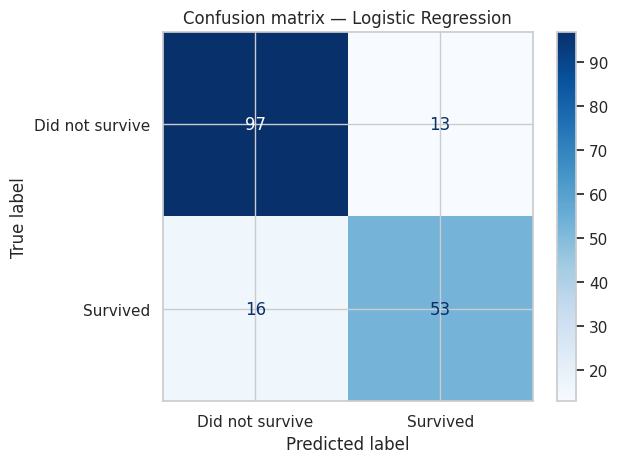

                 precision    recall  f1-score   support

Did not survive       0.86      0.88      0.87       110
       Survived       0.80      0.77      0.79        69

       accuracy                           0.84       179
      macro avg       0.83      0.82      0.83       179
   weighted avg       0.84      0.84      0.84       179



In [15]:
cm = confusion_matrix(y_test, predictions)
ConfusionMatrixDisplay(cm, display_labels=['Did not survive', 'Survived']).plot(cmap='Blues')
plt.title('Confusion matrix — Logistic Regression')
plt.show()

print(classification_report(y_test, predictions, target_names=['Did not survive', 'Survived']))

**Reading the matrix** (rows = reality, columns = prediction):
- Of 110 non-survivors, 97 were correctly identified (88%); 13 were wrongly predicted to survive.
- Of 69 survivors, 53 were found (**recall 77%**); 16 were wrongly predicted not to survive.

The model is better at spotting non-survivors, which makes sense since they were the majority (62%) of the training data. The missed survivors are likely "against-the-odds" cases, such as men in 3rd class who survived.

## 9. Model comparison & overfitting
Two tree-based models, first with default settings:

In [16]:
def evaluate(models):
    rows = []
    for name, m in models.items():
        m.fit(X_train, y_train)
        rows.append({'Model': name,
                     'Train %': round(m.score(X_train, y_train) * 100, 1),
                     'Test %':  round(m.score(X_test, y_test) * 100, 1)})
    out = pd.DataFrame(rows)
    out['Gap'] = out['Train %'] - out['Test %']
    return out

evaluate({
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree':       DecisionTreeClassifier(random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=42),
})

,Model,Train %,Test %,Gap
0,Logistic Regression,83.4,83.8,-0.4
1,Decision Tree,98.7,77.7,21.0
2,Random Forest,98.7,79.9,18.8


🚨 **Overfitting detected.** Both tree models score ~99% on training data but drop sharply on the test set: they memorized individual passengers instead of learning general patterns.

**Fix:** limit tree depth (`max_depth=5`), a *hyperparameter* that forces the trees to keep only the most general rules.

In [17]:
evaluate({
    'Logistic Regression':     LogisticRegression(max_iter=1000),
    'Decision Tree (depth 5)': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest (depth 5)': RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42),
})

,Model,Train %,Test %,Gap
0,Logistic Regression,83.4,83.8,-0.4
1,Decision Tree (depth 5),86.9,81.0,5.9
2,Random Forest (depth 5),85.0,82.1,2.9


Limiting depth closed the gap and **improved** test accuracy for both tree models. Even so, **Logistic Regression remains the best model** on this small dataset: more complex doesn't always mean better.

## 10. Predictions on new passengers
A helper function builds a passenger row with exactly the same 17 columns, in the same order, as the training data.

In [18]:
def make_passenger(pclass, sex, age, sibsp, parch, fare, has_cabin, embarked, title):
    data = {
        'Pclass': pclass,
        'Sex': 1 if sex == 'female' else 0,
        'Age': age,
        'SibSp': sibsp,
        'Parch': parch,
        'Fare': fare,
        'HasCabin': has_cabin,
        'FamilySize': sibsp + parch + 1,
        'IsAlone': 1 if (sibsp + parch) == 0 else 0,
        f'Embarked_{embarked}': 1,
        f'Title_{title}': 1,
    }
    return pd.DataFrame([data]).reindex(columns=X.columns, fill_value=0)

passengers = {
    '1st-class woman':             make_passenger(1, 'female', 30, 1, 0, 80, 1, 'C', 'Mrs'),
    '3rd-class man, alone':        make_passenger(3, 'male',   22, 0, 0,  8, 0, 'S', 'Mr'),
    '2nd-class boy with parents':  make_passenger(2, 'male',    6, 0, 2, 25, 0, 'S', 'Master'),
    'Me — 3rd class, alone':       make_passenger(3, 'female', 39, 0, 0,  8, 0, 'S', 'Miss'),
    'Me — upgraded to 1st class':  make_passenger(1, 'female', 39, 0, 0, 80, 0, 'S', 'Miss'),
}

for name, p in passengers.items():
    prob = model.predict_proba(p)[0][1] * 100
    verdict = "✅ SURVIVES" if model.predict(p)[0] == 1 else "❌ does not survive"
    print(f"{name:28} → {verdict:20} (survival probability: {prob:.1f}%)")

1st-class woman              → ✅ SURVIVES           (survival probability: 97.4%)
3rd-class man, alone         → ❌ does not survive   (survival probability: 9.6%)
2nd-class boy with parents   → ✅ SURVIVES           (survival probability: 78.1%)
Me — 3rd class, alone        → ❌ does not survive   (survival probability: 45.4%)
Me — upgraded to 1st class   → ✅ SURVIVES           (survival probability: 83.3%)


The predictions match the EDA findings exactly. The *what-if* test at the end is my favorite: the **same passenger** goes from ~45% to ~83% just by upgrading from a 3rd- to a 1st-class ticket. On the Titanic, the ticket price was literally a matter of life and death. 💸

## 11. Explainability: what did the model learn?
Logistic Regression coefficients show how much each feature pushes the prediction up (positive) or down (negative).

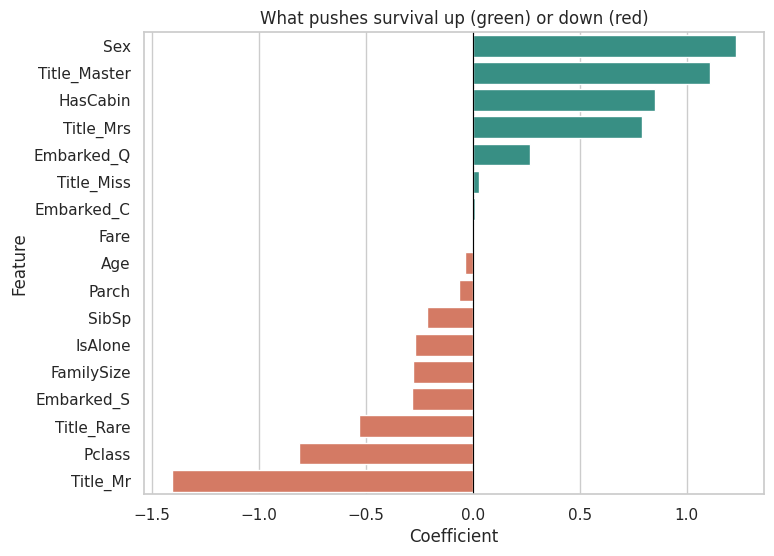

,Feature,Coefficient
1,Sex,1.229001
12,Title_Master,1.108944
6,HasCabin,0.851208
15,Title_Mrs,0.789928
10,Embarked_Q,0.266106
13,Title_Miss,0.030389
9,Embarked_C,0.010003
5,Fare,0.002419
2,Age,-0.035625
4,Parch,-0.063607


In [19]:
coefs = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_[0]}) \
          .sort_values('Coefficient', ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x='Coefficient', y='Feature', data=coefs,
            hue=coefs['Coefficient'] > 0, palette={True: '#2a9d8f', False: '#e76f51'}, legend=False)
plt.title('What pushes survival up (green) or down (red)')
plt.axvline(0, color='black', linewidth=0.8)
plt.show()
coefs

## ✅ Conclusions
- **Sex, title and ticket class** were the strongest predictors of survival, matching the historical "women and children first" rule and the class divide on board.
- **Feature engineering** (Title, FamilySize, HasCabin) turned messy raw columns into useful signals.
- **Logistic Regression** achieved **83.8% test accuracy** with no overfitting and beat both tree-based models.
- Unconstrained trees **overfit** (~99% train vs ~78–80% test); limiting `max_depth` reduced the gap and improved generalization.

### Next steps
- Cross-validation and `GridSearchCV` for more robust hyperparameter tuning
- Serve the model through a **Flask API** or a **Gradio** web app
- Try gradient boosting (XGBoost / LightGBM)